In [2]:
import pandas as pd
import numpy as np
from VaRData import VarData
from VaRMethods import GarchSim
from VaRBacktesting import VarBacktest
from datetime import datetime

## <center>Volatility Factor Project</center>

<p><b>Overview:</b> the Volatility Factor project is comprised of several python modules (dot.py files), a configuration file (dot.YML) for user-provided configurations and arguments, and input data (dot.csv file).  To 'operationalize' the project for production use, where users not proficient in Python may be required to generate output, we designed the project to limit user-interaction with the code by restricting the entry-point to the configuration file.  The configuration file works like a text-base user-interface - users can change arguments for relevant parameters to generate the desired output.  Once the user has set the arguments in the configuration file, a single runner script (volatility_factor_main.ipynb) is executed to generate the output.  This script imports other internally developed modules and third-party packages required to generate the desired output.  Please refer to <i>GARCH Simulation - Volatility Factor - MDA Departmental Procedures </i> for operating procedures and <i>GARCH Simulation - Technical Documentation</i> for technical details.

<p><b>Purpose:</b> the purpose of this document is to describe and provide illustrative examples of the functionality within the modules.  By design, both the project and model were constructed to be both flexible and extenable; as such, it's not feasible to discuss every permutation or available use-case.  However, this will provide an overview of general functionality and focus on it's use to estimate the FHLBank's Volatility Factor.  <b>Note:</b> this document is NOT procedural (it does not cover how users will generate the output for production use).  See <i>GARCH Simulation - Volatility Factor - MDA Departmental Procedures </i> for operating procedures.</p>

<p><b>Componets:</b> the project is primarily comprised of the following componets, which are described in greater detail herein.</p>

**1. VaRData.py:** this module contains the VaRData class.  It provides various measures and/or descriptive attributes for the index pricing.  All critical inherit from the VaRData class.

**2. VarMethods.py:** this module contains the GarchSim class which encapsulates the required data and methods required to by the model to estimate the Volatility Factor.   

**3. VaRBacktesting.py:** this module contains the VarBacktest class with methods to calculate various backtesting measures and plots.

**4. constants.py:** this module will contain contants for use in other modules.  Currently, only a single object is created in this module (CONFIGS).  

**5. util_functions.py**: this module encapsulates helper functions used in the runner script, <i>volatility_factor_main.ipynb</i>.  For instance, it contains a function to create a list of sample periods which can be used for iteration.

---
---
---

## <center>VaRData</center>

<p><b>Description:</b> this module reads the index pricing data (pricing_data_combined.csv) and assigns the resulting dataframe to a global variable DATA. These data are used in the VaRData class to compute measures and/or descriptive attributes of the index prices (via cached properties).  These properties generally fall into one of two categories:</p> 

**1. price measures:** prices, price returns, log returns, etcetera.  These measures are calculated from the data in pricing_data_combined.csv (DATA).

**2. descriptors:** ticker description, pricing index description, etcetera.  These attributes are sourced from either the pricing_dat_combined.csv or the var_config_volfactor.yml (CONFIGS).

<br> Below we provide some examples to illustrate some features of this class on a stand-alone basis.

---

**Example:** Instantiate VaRData

In [4]:
vdata = VarData(tickers = ["CB10"], weights= None)
print(type(vdata))

<class 'VaRData.VarData'>


---

**Example**: ticker data type validation checks

In [6]:
vdata1 = VarData(tickers = "CB10") #<-------------Accepts string
print(type(vdata1))
print(id(vdata1))
vdata2 = VarData(tickers = ["CB10"]) #<-----------Accepts list
print(type(vdata2))
print(id(vdata2))
vdata3 = VarData(tickers = ("CB10")) #<-----------Accepts tuple
print(type(vdata3))
print(id(vdata3))
#vdata = VarData(tickers=set("CB10")) #<----------UNCOMMENT TO VIEW ERROR

<class 'VaRData.VarData'>
2267822923840
<class 'VaRData.VarData'>
2267822924272
<class 'VaRData.VarData'>
2267822924608


---

**Example:** weights value validation checks

In [7]:
vdata = VarData(tickers = "CB10") #<---single-index w/o weights; weights value default to None - assigns 1 to weights
print(vdata.weights)
vdata = VarData(tickers = ["CB10", "CB20"]) #<-multi-index w/o weights; assigns equal weights
print(vdata.weights)
vdata = VarData(tickers = "CB10", weights = 2) #<--single-index with invalid weight; weights value defaults to 1 
print(vdata.weights)
#vdata = VarData(tickers = ["CB10", "CB20"], weights = [1,2]) #<-------UNCOMMENT TO VIEW ERROR
#print(vdata.weights)

1
[0.5 0.5]
1


---

**Example:** Available Properties<br>
The following properties are available using dot notation

In [13]:
print("Index Pricing Ticker\n")
print(f"{vdata.tickers}")
print(f"{type(vdata.tickers)}")
print("---------------------------------\n")

print("Index Weights\n")
print(f"{vdata.weights}")
print(f"{type(vdata.weights)}")
print("---------------------------------\n")

print("Single Index Indicator\n")
print(f"{vdata.single_index}")
print(f"{type(vdata.single_index)}")
print("---------------------------------\n")

print("Description of Pricing Index\n")
print(f"{vdata.index_description}")
print(f"{type(vdata.index_description)}")
print("---------------------------------\n")

print("Description of Ticker Pricing\n")
print(f"{vdata.ticker_description}")
print(f"{type(vdata.ticker_description)}")
print("---------------------------------\n")

print("MDA-assigned Volatility Factor ID\n")
print(f"{vdata.volatility_factor_id}")
print(f"{type(vdata.volatility_factor_id)}")
print("---------------------------------\n")

print("Index Prices\n")
print(f"{vdata.price_matrix.head(2)}")
print(f"{type(vdata.price_matrix)}")
print("---------------------------------\n")

print("One-Day Price Change\n")
print(f"{vdata.price_return_matrix.head(2)}")
print(f"{type(vdata.price_return_matrix)}")
print("---------------------------------\n")

print("Weighted One-Day Price Change\n")
print(f"{vdata.wtd_price_return.head(2)}")
print(f"{type(vdata.wtd_price_return)}")
print("---------------------------------\n")

print("\Logrithim of Price\n")
print(f"{vdata.log_price_matrix.head(2)}")
print(f"{type(vdata.log_price_matrix)}")
print("---------------------------------\n")

print("One-Day Log Return\n")
print(f"{vdata.log_return_matrix.head(2)}")
print(f"{type(vdata.log_return_matrix)}")
print("---------------------------------\n")

print("Weighted One-Day Log Return\n")
print(f"{vdata.wtd_log_return.head(2)}")
print(f"{type(vdata.wtd_log_return)}")
print("---------------------------------\n")

Index Pricing Ticker

['CB10']
<class 'list'>
---------------------------------

Index Weights

1
<class 'numpy.ndarray'>
---------------------------------

Single Index Indicator

True
<class 'bool'>
---------------------------------

Description of Pricing Index

ICE BofA AAA US Fixed Rate CMBS Index (CB10)
<class 'str'>
---------------------------------

Description of Ticker Pricing

CB10
<class 'str'>
---------------------------------

MDA-assigned Volatility Factor ID

cmbs_fixed_aaa
<class 'str'>
---------------------------------

Index Prices

            CB10
Date            
2000-01-03  95.1
2000-01-04  95.4
<class 'pandas.core.frame.DataFrame'>
---------------------------------

One-Day Price Change

                CB10
Date                
2000-01-04  0.003145
2000-01-05 -0.005587
<class 'pandas.core.frame.DataFrame'>
---------------------------------

Weighted One-Day Price Change

            Wtd_Price_Return
Date                        
2000-01-04          0.003145
2000

---
---
---

## <center>VarMethods</center>

<p><b>Description:</b> this module contains the <b>GarchSim</b> class used to estimate the Volatility Factor.  There are two primary componets used to calculate the volatility factor using the methods available in this class:<b> (1) estimation of the model</b>; and <b>(2) simulation processes.</b></p>

<p><b>Estimation:</b> we use a third-party package <a href="https://arch.readthedocs.io/en/latest/" target="_top">ARCH</a> to estimate the GARCH (1,1) model.  All of the simulation methods within the class are dependent on various objects and attributes of classes created when fitting the model.  As such, we persist all of the required data (and the .fit object itself) as pseudo read-only properties for access in when the simulation methods are called.  

<br> Below we provide some examples to illustrate some features of this class on a stand-alone basis.

---

**Example:** Instantiate GarchSim

In [10]:
gsim = GarchSim(tickers = ["M0A0"], weights = None, sample_start = "2013-10-01", sample_end = "2022-09-30")

---

### <center>Estimation</center>

Once instantiated, the following properties below are available.  Note: these are pseudo-read-only properties that are cached and lazy evaluated (they're all calculated when accessed).  They're calculated when the <i>_estimate_garch()</i> method is called.

In [15]:
print("Training data (one-day log-return)\n")
print(gsim.training_data.head(2))
print(f"{type(gsim.training_data)}")
print("---------------------------------\n")

print("Training data scaled (training data * y_scale)\n")
print(gsim.training_data_scaled.head(2))
print(f"{type(gsim.training_data_scaled)}")
print("---------------------------------\n")

print("Scale: y-scale value used to scale training data\n")
print(gsim.yscale)
print(f"{type(gsim.yscale)}")
print("---------------------------------\n")

print("Convergence Code: meta-data from loglikelihood optimization result\n")
print(gsim.convergence_codes)
print(f"{type(gsim.convergence_codes)}")
print("---------------------------------\n")

print("Coefficients\n")
print(gsim.coefficients)
print(f"{type(gsim.coefficients)}")
print("---------------------------------\n")

print("Conditional Volatility\n")
print(gsim.conditional_vol.head(2))
print(f"{type(gsim.conditional_vol)}")
print("---------------------------------\n")

print("Residuals\n")
print(gsim.residuals.head(2))
print(f"{type(gsim.residuals)}")
print("---------------------------------\n")

print("Standardized Residuals\n")
print(gsim.std_residuals.head(2))
print(f"{type(gsim.std_residuals)}")
print("---------------------------------\n")

print("Standardized Returns\n")
print(gsim.std_returns.head(2))
print(f"{type(gsim.std_returns)}")

Training data (one-day log-return)

                M0A0
Date                
2013-10-01 -0.000096
2013-10-02  0.000575
<class 'pandas.core.frame.DataFrame'>
---------------------------------

Training data scaled (training data * y_scale)

                M0A0
Date                
2013-10-01 -0.095937
2013-10-02  0.575484
<class 'pandas.core.frame.DataFrame'>
---------------------------------

Scale: y-scale value used to scale training data

[1000]
<class 'list'>
---------------------------------

Convergence Code: meta-data from loglikelihood optimization result

[0]
<class 'list'>
---------------------------------

Coefficients

[[0.043450709548828556, 0.11174946967885584, 0.8784296437255443]]
<class 'list'>
---------------------------------

Conditional Volatility

                M0A0
Date                
2013-10-01  1.733904
2013-10-02  1.638722
<class 'pandas.core.frame.DataFrame'>
---------------------------------

Residuals

                M0A0
Date                
2013-10-0

---

In addition to the properties above, the return object from the <i>archmodel.fit(*args)</i> method - the object used to derive many of the aformentioned properties, is also persisted.  We illustrate some of the properties in the example below, where we assign garch_fit to the variable _fit

Estimation output



<class 'statsmodels.iolib.summary.Summary'>
"""
                       Zero Mean - GARCH Model Results                        
==============================================================================
Dep. Variable:                   M0A0   R-squared:                       0.000
Mean Model:                 Zero Mean   Adj. R-squared:                  0.000
Vol Model:                      GARCH   Log-Likelihood:               -4126.86
Distribution:                  Normal   AIC:                           8259.72
Method:            Maximum Likelihood   BIC:                           8276.91
                                        No. Observations:                 2281
Date:                Wed, Jan 25 2023   Df Residuals:                     2281
Time:                        10:02:39   Df Model:                            0
                              Volatility Model                              
============================================================================
                 coef    std err          t      P>|t|      95.0% Conf. Int.
----------------------------------------------------------------------------
omega          0.0435  1.875e-02      2.318  2.048e-02 [6.704e-03,8.020e-02]
alpha[1]       0.1117  2.088e-02      5.352  8.680e-08   [7.083e-02,  0.153]
beta[1]        0.8784  2.232e-02     39.363      0.000     [  0.835,  0.922]
============================================================================

Covariance estimator: robust
"""

---------------

Coeffients



omega       0.043451
alpha[1]    0.111749
beta[1]     0.878430
Name: params, dtype: float64

---------------

Plots

---------------



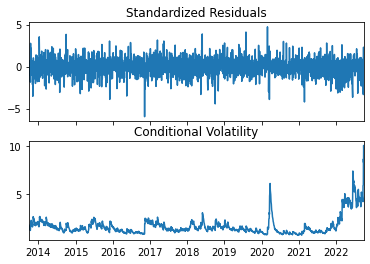

In [16]:
_fit = gsim.garch_fit[0] #<---persisted in list.  Single element for single-index.

print("Estimation output\n")
display(_fit.summary())
print("---------------\n")

print("Coeffients\n")
display(_fit.params)
print("---------------\n")


print("Plots\n")
display(fig=_fit.plot())
print("---------------\n")


---

### <center>Simulation</center>

Once the model is specified and fit using the Arch package, a simulation processes generates forward-looking one-day price paths.  The one-day price paths are then transformed to n-day price change paths as setforth in the model documentation.  The purpose of this section is to outline some of the different types of simulations the model was designed to accomodate.  These simulations are invoked by passing one of the following arguments to the <i>shock_type</i> parameter of the <i>CustomNDayPriceSimulation</i> method.<br>

**1. normal:** this simulation process draws the exogenous shocks from a standard normal distribution for the entire duraction of the forecast (horizon 1 + horizon 2 + ndays - 1).

**2. custom_normal:** <u><b>this is the simulation process used to derive the long-term VaR - the volatility factor used for the annual review period</u></b>.  It is idential to the "Normal" simulation - it draws the exogenous shocks from a standard normal distribution for the entire duration of the forecast.  However, we impose stress to the shocks for periods 64 through 68 by by multiplying them by $\sqrt{2}$.  This process is described in detail in section 3.3.1 of the <i>GARCH Simulation - Technical Documentation</i>.

**3. bootstrap:** Unlike the simulation processes described above - both of which assume $e_t$ follow a standard norml distribution - this process draws from the fitted values of $e_t$ from a user-defined date range.  When <i>shock_type</i> is set to <i>bootstrap</i>, users must provide two additional arguments to the <i>bootstrap_start</i> and the <i>bootstrap_end</i> parameters.

**4. custom_bootstrap:** This simulation process combines the <i>normal</i> and the <i>bootstrap</i> simulation processes described above.  For the first <i>horizon1</i> periods, shocks are drawn from the fitted values of $e_t$ from a user-defined date range passed to the <i>bootstrap_start</i> and the <i>bootstrap_end</i> parameters, and for the remainder of the simulation, the the shocks are drawn from a standard normal distribution.

#### <center>Simulation - Starting Values</center>

All of the different simulation types described above can be executed without setting the starting values of $ϵ_0$ and $α_0$.  When the <i>start_vals</i> parameter is unchanged from it's default value of None, the last fitted values for ϵ and α are used in the simulation.  To specify the starting values, a two-element list must be passed to the <i>start_vals</i> parameter; the first element with a date and the second element with a quantile.  When a user provides values for the <i>start_vals</i> parameter, a one-day variance forecast is performed for each business day from the date provided through the end of the sample period.  The values of $ϵ_0$ and $α_0$ are set to the corresponding quantile of the series of one-day variance forecasts.  <u><b>For the long-term VaR - the volatility factor used for the annual review period - the values of $ϵ_0$ and $α_0$ are set to the 50th quantile of the one-day variance forecast over the last year in the sampele period.</u></b>. 


---

**Start:** to begin, we'll instantiate an instance of GarchSim using the same values used above.

In [17]:
v = GarchSim(tickers = ["M0A0"], weights = None, sample_start = "2013-10-01", sample_end = "2022-09-30") #instantiate GarchSim

---

**Next:** next, we'll assign some values to variables to use in the CustomNDayPriceSimulation method.

In [1]:
horizon1, horizon2, ndays, nsims = [63, 252, 10, 10000] #required args for CustomNDayPriceSimulation
horizon2 = horizon2 + ndays - 1 #For 'horizon2' parameter.
starting_values = ["2021-10-01", 0.50] #for 'start_vals' parameter

---

**Last:** we'll demonstrate the simulations outlined above.

---

#### <center>normal (no starting values set)</center>

In [23]:
var = v.CustomNDayPriceSimulation(horizon1 = horizon1, horizon2 = horizon2, ndays = ndays, nsims = nsims, 
                                shock_type = "normal")
display(var)

{'Tickers': 'M0A0',
 'Weights': '1',
 'SampleStart': '2013-10-01',
 'SampleEnd': '2022-09-30',
 'BootstrapStart': None,
 'BootstrapEnd': None,
 'ShockType': 'normal',
 'VaRp': '99Q',
 'MeanModel': 'Zero',
 'VolatilityModel': 'Garch',
 'Method': 'GarchSim_normal',
 'Horizon1': 63,
 'Horizon2': 261,
 'NDays': 10,
 'Simulations': 10000,
 'StartingValueQ': 'None',
 'StartingValueDate': 'None',
 'ConvergencyCode': '0',
 'LogVaR_50': 1.9939,
 'LogVaR_75': 3.1344,
 'LogVaR_95': 4.0724,
 'LogVaR_99': 12.095,
 'VaR_50': 1.9741,
 'VaR_75': 3.0858,
 'VaR_95': 6.4746,
 'VaR_99': 11.3922}

#### <center>normal (WITH starting values set)</center>

In [ ]:
var = v.CustomNDayPriceSimulation(horizon1 = horizon1, horizon2 = horizon2, ndays = ndays, nsims = nsims, 
                                shock_type = "normal", start_vals=starting_values)
display(var)

---

#### <center>custom_normal (no starting values set)</center>

In [24]:
var = v.CustomNDayPriceSimulation(horizon1 = horizon1, horizon2 = horizon2, ndays = ndays, nsims = nsims, 
                                shock_type = "custom_normal")
display(var)

{'Tickers': 'M0A0',
 'Weights': '1',
 'SampleStart': '2013-10-01',
 'SampleEnd': '2022-09-30',
 'BootstrapStart': None,
 'BootstrapEnd': None,
 'ShockType': 'custom_normal',
 'VaRp': '99Q',
 'MeanModel': 'Zero',
 'VolatilityModel': 'Garch',
 'Method': 'GarchSim_custom_normal',
 'Horizon1': 63,
 'Horizon2': 261,
 'NDays': 10,
 'Simulations': 10000,
 'StartingValueQ': 'None',
 'StartingValueDate': 'None',
 'ConvergencyCode': '0',
 'LogVaR_50': 2.3598,
 'LogVaR_75': 3.8857,
 'LogVaR_95': 5.1346,
 'LogVaR_99': 16.1869,
 'VaR_50': 2.3322,
 'VaR_75': 3.8112,
 'VaR_95': 8.3531,
 'VaR_99': 14.9448}

#### <center>custom_normal (WITH starting values set)</center>

In [ ]:
var = v.CustomNDayPriceSimulation(horizon1 = horizon1, horizon2 = horizon2, ndays = ndays, nsims = nsims, 
                                shock_type = "custom_normal", start_vals=starting_values)
display(var)

---

#### <center>bootstrap (no starting values set)</center>

In [25]:
var = v.CustomNDayPriceSimulation(horizon1 = horizon1, horizon2 = horizon2, ndays = ndays, nsims = nsims, 
                                shock_type = "bootstrap", bootstrap_start = "2021-04-01", bootstrap_end = "2022-03-31")
display(var)

{'Tickers': 'M0A0',
 'Weights': '1',
 'SampleStart': '2013-10-01',
 'SampleEnd': '2022-09-30',
 'BootstrapStart': '2021-04-01',
 'BootstrapEnd': '2022-03-31',
 'ShockType': 'bootstrap',
 'VaRp': '99Q',
 'MeanModel': 'Zero',
 'VolatilityModel': 'Garch',
 'Method': 'GarchSim_bootstrap',
 'Horizon1': 63,
 'Horizon2': 261,
 'NDays': 10,
 'Simulations': 10000,
 'StartingValueQ': 'None',
 'StartingValueDate': 'None',
 'ConvergencyCode': '0',
 'LogVaR_50': 2.9623,
 'LogVaR_75': 4.9069,
 'LogVaR_95': 6.7653,
 'LogVaR_99': 24.4681,
 'VaR_50': 2.9189,
 'VaR_75': 4.7884,
 'VaR_95': 11.4112,
 'VaR_99': 21.7046}

#### <center>bootstrap (WITH starting values set)</center>

In [ ]:
var = v.CustomNDayPriceSimulation(horizon1 = horizon1, horizon2 = horizon2, ndays = ndays, nsims = nsims, 
                                shock_type = "bootstrap", bootstrap_start = "2021-04-01", bootstrap_end = "2022-03-31",
                                start_vals=starting_values)
display(var)

---

#### <center>custom_bootstrap (no starting values set)</center>

In [26]:
var = v.CustomNDayPriceSimulation(horizon1 = horizon1, horizon2 = horizon2, ndays = ndays, nsims = nsims, 
                                shock_type = "custom_bootstrap", bootstrap_start = "2022-07-01", bootstrap_end = "2022-09-30")
display(var)

{'Tickers': 'M0A0',
 'Weights': '1',
 'SampleStart': '2013-10-01',
 'SampleEnd': '2022-09-30',
 'BootstrapStart': '2022-07-01',
 'BootstrapEnd': '2022-09-30',
 'ShockType': 'custom_bootstrap',
 'VaRp': '99Q',
 'MeanModel': 'Zero',
 'VolatilityModel': 'Garch',
 'Method': 'GarchSim_custom_bootstrap',
 'Horizon1': 63,
 'Horizon2': 261,
 'NDays': 10,
 'Simulations': 10000,
 'StartingValueQ': 'None',
 'StartingValueDate': 'None',
 'ConvergencyCode': '0',
 'LogVaR_50': 4.5095,
 'LogVaR_75': 8.5247,
 'LogVaR_95': 12.1795,
 'LogVaR_99': 48.8856,
 'VaR_50': 4.4093,
 'VaR_75': 8.1715,
 'VaR_95': 19.9452,
 'VaR_99': 38.6672}

#### <center>custom_bootstrap (WITH starting values set)</center>

In [ ]:
var = v.CustomNDayPriceSimulation(horizon1 = horizon1, horizon2 = horizon2, ndays = ndays, nsims = nsims, 
                                shock_type = "custom_bootstrap", bootstrap_start = "2022-07-01", bootstrap_end = "2022-09-30",
                                start_vals=starting_values)
display(var)

---

---
---
---

## <center>VarBacktesting</center>

<p><b>Description:</b> this module contains the <b>VarBacktest</b> class.  This class contains various methods and properties used to generate different backtesting measures and to generate plots.  It follows the same general recipe as the <b>VaRData</b> module: getter/setter decorators for validation with cached properties.


---

**Example:** Price Plot & Price Change Plot <br>

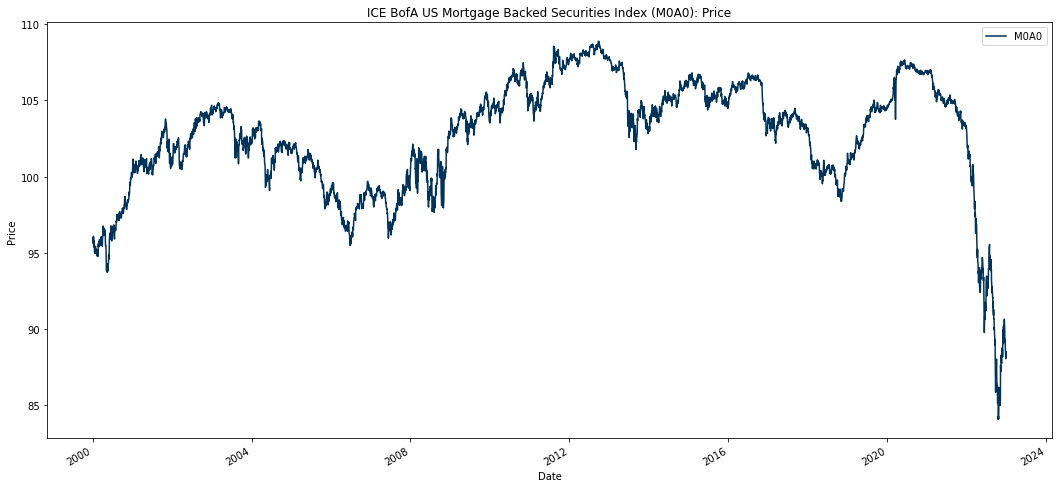

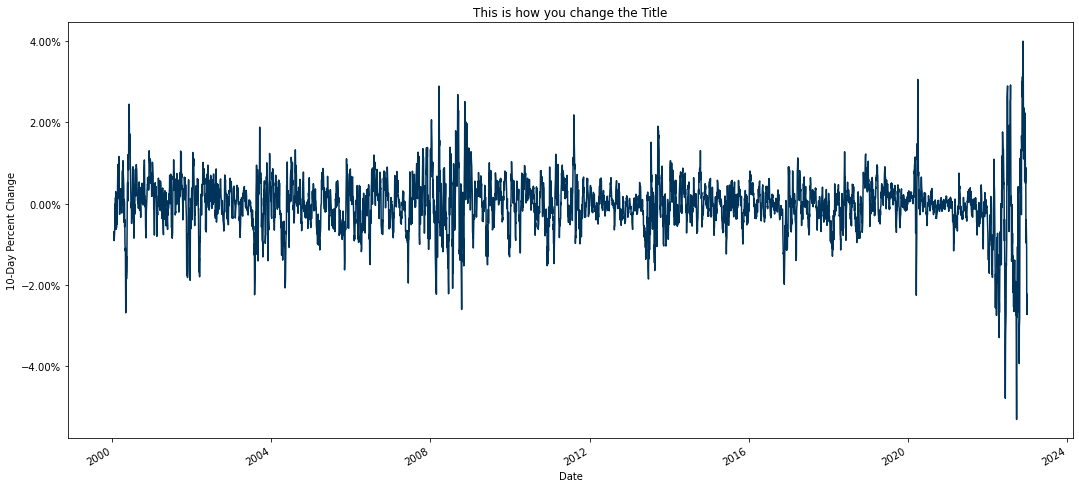

In [29]:
bt = VarBacktest(tickers = "M0A0", n_liquidation = 10) #instantiate bt
bt.price_plot() #<------------default title; Note: this is only method that works without any optional arguments
bt.price_change_plot(title_text="This is how you change the Title") #<-----user-defined title

---

**Example:** Backtest plot

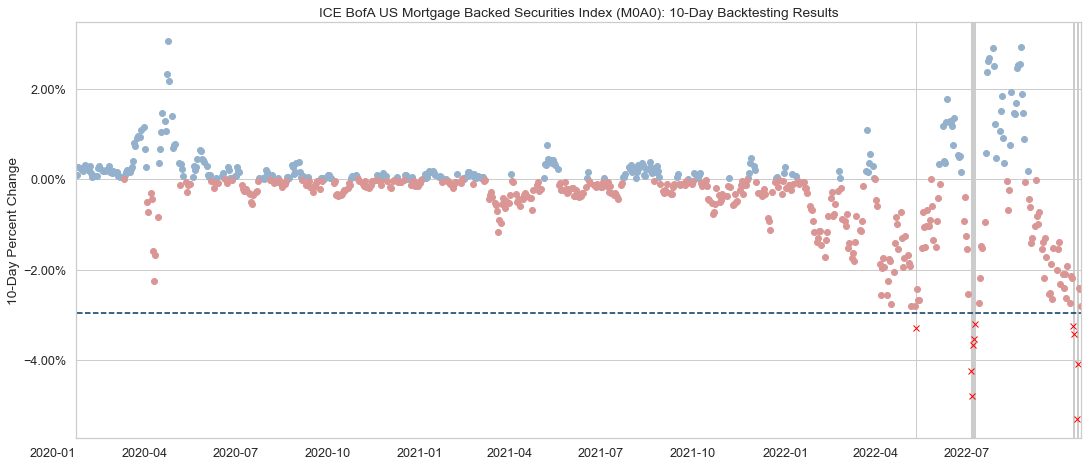

In [31]:
bt = VarBacktest(tickers = "M0A0", n_liquidation = 10, VaR = 3, start_date="2020-01-01", end_date="2022-09-30")
bt.backtest_plot()

---

**Example:** Available Properties<br>
The following properties are available using dot notation.

In [32]:
print("VaR Percentage\n")
display(bt.var_pct) 
print("---------------\n")

print("N-Day Arithmetic Return\n")
display(bt.nday_price_return.head(2))
print("---------------\n")

print("N-Day Log Return\n")
display(bt.nday_log_return.head(2))
print("---------------\n")

print("Breaks\n")
display(bt.break_series.head(2))
print("---------------\n")

print("Shortfalls\n")
display(bt.shortfall_series.head(2))

VaR Percentage



0.029554466451491845

---------------

N-Day Arithmetic Return



Date
2020-01-02    0.000957
2020-01-03    0.002779
dtype: float64

---------------

N-Day Log Return



Date
2020-01-02    0.000957
2020-01-03    0.002775
dtype: float64

---------------

Breaks



Date
2020-01-02    0
2020-01-03    0
dtype: int32

---------------

Shortfalls



Date
2020-01-02    0.030512
2020-01-03    0.032333
dtype: float64